In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.io import arff

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss,
    precision_recall_curve, precision_score, recall_score,
    fbeta_score, balanced_accuracy_score, confusion_matrix,
    classification_report
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_validate,
    RandomizedSearchCV, cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from xgboost import XGBClassifier


RANDOM_STATE = 42
PLIK = Path("5year.arff")  

rekordy, meta = arff.loadarff(str(PLIK))
kolumny = [n for n in rekordy.dtype.names if n != "class"]
X = pd.DataFrame({n: rekordy[n].astype(float) for n in kolumny})
y = pd.Series([int(k.decode("ascii")) for k in rekordy["class"]], name="class")

# Identyczne wiersze (łącznie z etykietą) usuwamy przed podziałem.
dane = X.copy()
dane["class"] = y
print("Surowych rekordów:", len(dane))
print("Duplikaty X + y:", int(dane.duplicated().sum()))
dane = dane.drop_duplicates().reset_index(drop=True)
y = dane.pop("class").astype(int)
X = dane
print("Po usunięciu duplikatów:", X.shape)
print("Bankructwa:", int(y.sum()), "udział:", round(y.mean() * 100, 2), "%")

Surowych rekordów: 5910
Duplikaty X + y: 60
Po usunięciu duplikatów: (5850, 64)
Bankructwa: 408 udział: 6.97 %


In [2]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "pozytywne:", int(y_train.sum()))
print("Test:", X_test.shape, "pozytywne:", int(y_test.sum()))

Train: (4680, 64) pozytywne: 326
Test: (1170, 64) pozytywne: 82


In [3]:
class QuantileClipper(BaseEstimator, TransformerMixin):
    """Winsoryzacja każdej kolumny do percentyli obliczonych w fit()."""
    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        a = np.asarray(X, dtype=float)
        self.lower_ = np.nanquantile(a, self.lower, axis=0)
        self.upper_ = np.nanquantile(a, self.upper, axis=0)
        return self

    def transform(self, X):
        a = np.asarray(X, dtype=float)
        return np.clip(a, self.lower_, self.upper_)

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

def przygotowanie(skalowanie=False, winsoryzacja=True):
    kroki_num = []
    if winsoryzacja:
        kroki_num.append(("clip", QuantileClipper(0.01, 0.99)))
    kroki_num.append(("impute", SimpleImputer(strategy="median", add_indicator=True)))
    if skalowanie:
        kroki_num.append(("scale", RobustScaler()))

    transformatory = [("numeric", Pipeline(kroki_num), num_cols)]
    if cat_cols:
        transformatory.append(("categoric", Pipeline([
            ("impute", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), cat_cols))
    return ColumnTransformer(
        transformatory, remainder="drop", sparse_threshold=0.0
    )

def potok(model, skalowanie=False, winsoryzacja=True):
    return Pipeline([
        ("preprocess", przygotowanie(skalowanie, winsoryzacja)),
        ("model", model)
    ])

sprawdzenie danych i importy

In [4]:
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    fbeta_score,
    confusion_matrix,
)

from xgboost import XGBClassifier

# Sprawdzamy zgodność danych.
assert len(X_train) == len(y_train)
assert X_train.index.equals(y_train.index)
assert set(y_train.unique()) == {0, 1}

liczba_0 = int((y_train == 0).sum())
liczba_1 = int((y_train == 1).sum())

print("Obserwacje treningowe:", len(X_train))
print("Bez bankructwa:", liczba_0)
print("Bankructwa:", liczba_1)
print("Stosunek klasy 0 do klasy 1:", round(liczba_0 / liczba_1, 2))

Obserwacje treningowe: 4680
Bez bankructwa: 4354
Bankructwa: 326
Stosunek klasy 0 do klasy 1: 13.36


Dla dotychczasowego podziału oczekujecie 4680 obserwacji, w tym 326 bankructw.

Komórka 2: ustalenie wspólnych warunków  
Używamy ustawień początkowej konfiguracji XGBoost z notebooka. Nie korzystamy tutaj z best_estimator_, żeby jasno zdefiniować punkt odniesienia.

In [5]:
RANDOM_STATE = 42

# Cztery warianty jednego parametru.
WAGI = [1, 3, 7, 13]

# Stały próg we wszystkich wariantach.
PROG = 0.5

# Pozostałe parametry są identyczne dla wszystkich wag.
model_bazowy = potok(
    XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        min_child_weight=5,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        scale_pos_weight=1,
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=2,
    ),
    skalowanie=False,
    winsoryzacja=True,
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

# Tworzymy podziały raz.
# Każda waga będzie oceniana na tych samych obserwacjach.
podzialy = list(cv.split(X_train, y_train))

print("Liczba wariantów:", len(WAGI))
print("Liczba foldów:", len(podzialy))
print("Łączna liczba treningów:", len(WAGI) * len(podzialy))

Liczba wariantów: 4
Liczba foldów: 5
Łączna liczba treningów: 20


To 20 treningów: cztery wagi × pięć foldów.

Próg 0.5 jest tutaj stałym punktem odniesienia, nie rekomendacją dla aplikacji. Nie zmieniamy jednocześnie wagi i progu, żeby nie mieszać ich efektów.

właściwe porównanie

In [6]:
wyniki = []

for waga in WAGI:
    print(f"\nSprawdzam scale_pos_weight = {waga}")

    for numer_folda, (idx_uczenie, idx_walidacja) in enumerate(
        podzialy, start=1
    ):
        # Części aktualnego podziału walidacyjnego.
        X_uczenie = X_train.iloc[idx_uczenie]
        y_uczenie = y_train.iloc[idx_uczenie]

        X_walidacja = X_train.iloc[idx_walidacja]
        y_walidacja = y_train.iloc[idx_walidacja]

        # Nowa, niedopasowana kopia całego potoku.
        model = clone(model_bazowy)

        # Zmieniamy tylko wagę klasy bankructwa.
        model.set_params(model__scale_pos_weight=waga)

        # Przetwarzanie i uczenie wyłącznie na części treningowej.
        model.fit(X_uczenie, y_uczenie)

        # Wyniki dla części walidacyjnej.
        p = model.predict_proba(X_walidacja)[:, 1]
        predykcje = (p >= PROG).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_walidacja,
            predykcje,
            labels=[0, 1],
        ).ravel()

        wyniki.append({
            "waga": waga,
            "fold": numer_folda,
            "prog": PROG,
            "AP": average_precision_score(y_walidacja, p),
            "ROC_AUC": roc_auc_score(y_walidacja, p),
            "precision": precision_score(
                y_walidacja, predykcje, zero_division=0
            ),
            "recall": recall_score(
                y_walidacja, predykcje, zero_division=0
            ),
            "F2": fbeta_score(
                y_walidacja, predykcje, beta=2, zero_division=0
            ),
            "TN": int(tn),
            "FP": int(fp),
            "FN": int(fn),
            "TP": int(tp),
        })

        print(
            f"  Fold {numer_folda}: "
            f"AP={wyniki[-1]['AP']:.3f}, "
            f"precision={wyniki[-1]['precision']:.3f}, "
            f"recall={wyniki[-1]['recall']:.3f}"
        )

wyniki_foldy = pd.DataFrame(wyniki)


Sprawdzam scale_pos_weight = 1
  Fold 1: AP=0.710, precision=0.879, recall=0.446
  Fold 2: AP=0.786, precision=0.809, recall=0.585
  Fold 3: AP=0.713, precision=0.909, recall=0.462
  Fold 4: AP=0.803, precision=0.900, recall=0.554
  Fold 5: AP=0.811, precision=0.921, recall=0.530

Sprawdzam scale_pos_weight = 3
  Fold 1: AP=0.705, precision=0.698, recall=0.569
  Fold 2: AP=0.783, precision=0.643, recall=0.692
  Fold 3: AP=0.723, precision=0.714, recall=0.615
  Fold 4: AP=0.801, precision=0.824, recall=0.646
  Fold 5: AP=0.818, precision=0.818, recall=0.682

Sprawdzam scale_pos_weight = 7
  Fold 1: AP=0.703, precision=0.580, recall=0.615
  Fold 2: AP=0.780, precision=0.538, recall=0.769
  Fold 3: AP=0.696, precision=0.571, recall=0.677
  Fold 4: AP=0.808, precision=0.721, recall=0.754
  Fold 5: AP=0.796, precision=0.693, recall=0.788

Sprawdzam scale_pos_weight = 13
  Fold 1: AP=0.681, precision=0.517, recall=0.708
  Fold 2: AP=0.776, precision=0.486, recall=0.815
  Fold 3: AP=0.683, p

Co oznaczają liczniki?
- TP — wykryte bankructwa.
- FN — bankructwa niewykryte.
- FP — fałszywe alarmy.
- TN — poprawnie rozpoznane przypadki bez bankructwa.  
Kod nie korzysta z X_test ani y_test.

podsumowanie i zapis wyników

In [7]:
podsumowanie = (
    wyniki_foldy
    .groupby("waga")
    .agg(
        AP_srednia=("AP", "mean"),
        AP_odch_std=("AP", "std"),
        ROC_AUC_srednia=("ROC_AUC", "mean"),
        precision_srednia=("precision", "mean"),
        recall_srednia=("recall", "mean"),
        F2_srednia=("F2", "mean"),
        wykryte_bankructwa=("TP", "sum"),
        pominiete_bankructwa=("FN", "sum"),
        falszywe_alarmy=("FP", "sum"),
    )
    .reset_index()
)

display(podsumowanie.round(4))

wyniki_foldy.to_csv(
    "xgboost_wagi_wyniki_foldow.csv",
    index=False,
)

podsumowanie.to_csv(
    "xgboost_wagi_podsumowanie.csv",
    index=False,
)

print("Zapisano wyniki eksperymentu.")

,waga,AP_srednia,AP_odch_std,ROC_AUC_srednia,precision_srednia,recall_srednia,F2_srednia,wykryte_bankructwa,pominiete_bankructwa,falszywe_alarmy
0,1,0.7644,0.0494,0.9470,0.8835,0.5153,0.5610,168,158,23
1,3,0.7661,0.0494,0.9479,0.7394,0.6410,0.6573,209,117,76
2,7,0.7566,0.0530,0.9458,0.6205,0.7207,0.6966,235,91,147
3,13,0.7473,0.0604,0.9443,0.5239,0.7728,0.7050,252,74,231


Zapisano wyniki eksperymentu.


Sumy dotyczą predykcji walidacyjnych dla całego treningu. Każda obserwacja była oceniona raz przez model, który jej nie widział podczas dopasowania. Nie są to wyniki jednego modelu na końcowym teście.

wykres

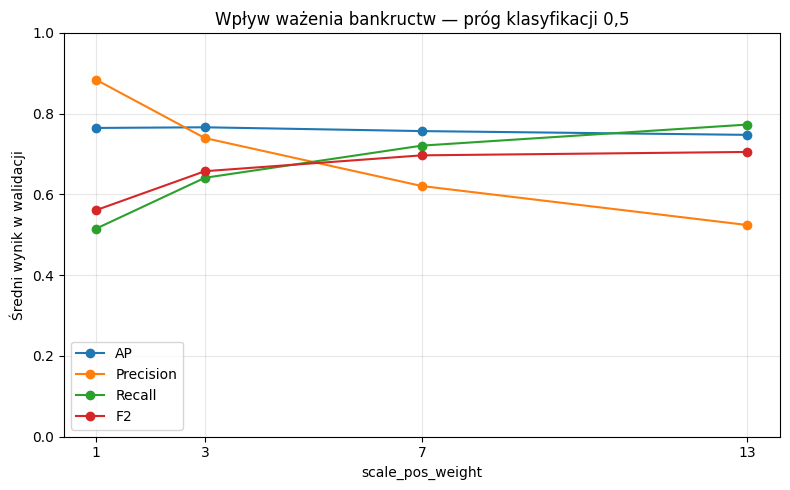

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

for kolumna, etykieta in [
    ("AP_srednia", "AP"),
    ("precision_srednia", "Precision"),
    ("recall_srednia", "Recall"),
    ("F2_srednia", "F2"),
]:
    ax.plot(
        podsumowanie["waga"],
        podsumowanie[kolumna],
        marker="o",
        label=etykieta,
    )

ax.set_xticks(WAGI)
ax.set_ylim(0, 1)
ax.set_xlabel("scale_pos_weight")
ax.set_ylabel("Średni wynik w walidacji")
ax.set_title("Wpływ ważenia bankructw — próg klasyfikacji 0,5")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
assert len(wyniki_foldy) == 20
assert len(podsumowanie) == 4
assert wyniki_foldy.groupby("waga").size().eq(5).all()

print("Wszystkie cztery warianty oceniono w pięciu foldach.")

Wszystkie cztery warianty oceniono w pięciu foldach.


1. Czy większa waga zwiększa recall?  
Czy wykrywacie większą część bankructw?

2. Co dzieje się z precision i fałszywymi alarmami?  
Czy poprawa wykrywania wiąże się z częstszym alarmowaniem dla firm bez bankructwa?

3. Czy rośnie AP?  
AP jest liczone z wyników modelu bez ustalania jednego progu klasyfikacji. Pozwala sprawdzić, czy poprawia się również jakość uporządkowania firm według ryzyka.

4. Czy różnice są stabilne między foldami?  
Sprawdź także szczegółowe wyniki. Minimalna przewaga średniej nie musi oznaczać wyraźnie lepszego rozwiązania.

## Wnioski

Zwiększanie `scale_pos_weight` poprawiało wykrywanie bankructw,
ale zwiększało liczbę fałszywych alarmów. Przy zmianie wagi z 1
na 13 średni recall wzrósł z **51,5% do 77,3%**, natomiast
precision spadła z **88,3% do 52,4%**. Wykryto o 84 bankructwa
więcej, kosztem 208 dodatkowych fałszywych alarmów.

Najwyższe średnie AP uzyskano dla wagi **3**, jednak przewaga nad
wagą 1 była niewielka. Waga **13** osiągnęła najwyższe F2,
premiujące wykrywanie bankructw.

**Nie ma jednego wariantu najlepszego pod każdym względem.**
Wybór zależy od tego, czy ważniejsze jest ograniczenie pominiętych
bankructw, czy fałszywych alarmów.

Wyniki dotyczą pięciokrotnej walidacji na treningu, przy progu
**0,5**. Kolejnym krokiem będzie sprawdzenie, czy obniżenie progu
dla modelu z wagą 1 pozwoli osiągnąć podobną czułość przy mniejszej
liczbie fałszywych alarmów.